# HEART – ECG Signal Preprocessing, QRS Detection, and Feature Extraction Pipeline
**Students:** Benedetta Tintori, Michele Ivo Galella  
**Course:** Data Mining and Machine Learning, University of Pisa  

This notebook implements the end-to-end signal processing, peak detection, and feature extraction pipeline for the **HEART (Heartbeat Extraction and Arrhythmia Recognition Tool)** project.
The pipeline comprises the following sequential stages:
1. **ECG Signal Preprocessing**: Automated download of raw records from the **PhysioNet MIT-BIH Arrhythmia Database** and noise mitigation using a **zero-phase Butterworth bandpass filter (0.5–45 Hz)**.
2. **QRS Complex Detection (Pan-Tompkins Algorithm)**: Extraction of the local energy envelope of the QRS complex via differentiation, squaring, and moving window integration, followed by local peak alignment to correct for filter-induced group delay.
3. **Detector Validation**: Quantitative validation of the QRS detector accuracy against physician annotations (ground truth) on benchmark record `111` using a standard clinical tolerance window of 50 ms.
4. **State-of-the-Art (SOTA) Feature Extraction**:
   - **Temporal / Rhythm Features (Local HRV)**: Pre-RR interval, Post-RR interval, RR-Ratio, local mean RR, and local heart rate variability (HRV) standard deviation computed over a sliding window of 10 beats.
   - **Morphological & Statistical Features**: R-peak amplitude ($mV$), skewness, and kurtosis calculated over a 200 ms window centered on the R-peak.
   - **Spectral Features (DWT)**: 3-level Discrete Wavelet Transform (DWT) decomposition using the Daubechies 4 (db4) mother wavelet to measure high-frequency spectral energy.
5. **Clinical Dataset Consolidation**: Mapping of the 19 raw annotation classes into the clinical **AAMI standard** (N, S, V, F classes) and partitioning the dataset via the **Inter-Patient split protocol (De Chazal)** to prevent data leakage.


In [1]:
%pip install -r ../requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [3]:
import os
# Force NumPy to use legacy promotion behavior to prevent wfdb OverflowError on newer NumPy versions
os.environ['NPY_PROMOTION_STATE'] = 'legacy'
import time
import numpy as np
import pandas as pd
import scipy.signal as signal
import scipy.stats as stats
import pywt
import matplotlib.pyplot as plt
import seaborn as sns

# Configure plot styling
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Inter', 'DejaVu Sans', 'Arial']

# Define local output directory
default_dir = '../data'

# Create output directory if it does not exist
os.makedirs(default_dir, exist_ok=True)
print(f"Output directory resolved to: {default_dir}")


Output directory resolved to: ../data


## 1. ECG Signal Preprocessing: Zero-Phase Butterworth Bandpass Filtering

Raw ECG recordings are typically contaminated by several distinct noise sources:
* **Baseline Wander (BLW)**: Low-frequency noise ($< 0.5$ Hz) caused by respiration and electrode-skin impedance variations.
* **Powerline Interference**: Narrowband noise at 50 Hz or 60 Hz from power grid coupling.
* **Electromyographic (EMG) Artifacts**: High-frequency muscle noise ($> 40$ Hz) arising from skeletal muscle activity.

To isolate the clinical frequency band of interest and preserve QRS morphology, we apply a **3rd-order Butterworth bandpass filter**. 

To prevent phase distortion and group delays that would shift the temporal positions of R-peaks, the filter is implemented bidirectionally (zero-phase) using `scipy.signal.filtfilt`. This double-filtering approach yields a zero-phase response and doubles the effective filter order (resulting in an effective 6th-order roll-off).

The selected cutoff frequencies are:
* **$f_{low} = 0.5$ Hz**: Attenuates baseline wander while preserving the low-frequency components of the P and T waves.
* **$f_{high} = 45.0$ Hz**: Attenuates high-frequency muscle noise and powerline interference.


In [ ]:
try:
    import wfdb
except ImportError:
    print("Installing wfdb library...")
    import subprocess
    subprocess.check_call(["pip", "install", "wfdb"])
    import wfdb

# Monkey-patch proc_core_fields in wfdb to prevent OverflowError on newer NumPy versions
import wfdb.io.annotation
def patched_proc_core_fields(filebytes, bpi):
    sample_diff = 0
    while filebytes[bpi, 1] >> 2 == 59:
        skip_diff = (
            (int(filebytes[bpi + 1, 0]) << 16)
            + (int(filebytes[bpi + 1, 1]) << 24)
            + (int(filebytes[bpi + 2, 0]) << 0)
            + (int(filebytes[bpi + 2, 1]) << 8)
        )
        if skip_diff > 2147483647:
            skip_diff = skip_diff - 4294967296
        sample_diff += skip_diff
        bpi = bpi + 3

    label_store = filebytes[bpi, 1] >> 2
    # Convert filebytes to int before multiplication and addition to prevent NumPy uint8 overflow
    sample_diff += int(filebytes[bpi, 0]) + 256 * int(filebytes[bpi, 1] & 3)
    bpi = bpi + 1
    return sample_diff, label_store, bpi

wfdb.io.annotation.proc_core_fields = patched_proc_core_fields

# Function to apply a zero-phase Butterworth bandpass filter
def apply_butterworth_filter(signal_data, fs, lowcut=0.5, highcut=45.0, order=3):
    nyq = 0.5 * fs
    low = lowcut / nyq
    high = highcut / nyq
    b, a = signal.butter(order, [low, high], btype='band')
    # Zero-phase filtering using filtfilt
    return signal.filtfilt(b, a, signal_data)

# Try multiple paths for local database directory
possible_db_dirs = [
    '../mit-bih-arrhythmia-database-1.0.0',
    './mit-bih-arrhythmia-database-1.0.0',
]
db_dir = None
for d in possible_db_dirs:
    if os.path.exists(d):
        db_dir = d
        break

if db_dir is not None:
    print(f"Local database directory resolved to: {db_dir}")
    # Extract digit-only record IDs from .hea files in local directory
    record_list = sorted(list(set([f.split('.')[0] for f in os.listdir(db_dir) if f.endswith('.hea') and f.split('.')[0].isdigit()])))
else:
    print("Local database not found. Will download records dynamically from PhysioNet.")
    record_list = wfdb.get_record_list('mitdb')

print(f"Found {len(record_list)} records in the database.")

# Preprocess all records and cache locally
print("\n--- Executing Preprocessing (Filtering & Caching) ---")
start_time = time.time()

# Loop through all records. Processing is skipped if files are already cached.
for record_id in record_list:
    npy_path = os.path.join(default_dir, f"{record_id}_filtered.npy")
    npz_path = os.path.join(default_dir, f"{record_id}_annotations.npz")
    
    if os.path.exists(npy_path) and os.path.exists(npz_path):
        continue
        
    if db_dir is not None:
        print(f"Processing local record: {record_id}...")
        record_path = os.path.join(db_dir, record_id)
        record = wfdb.rdsamp(record_path)
        annotation = wfdb.rdann(record_path, 'atr')
    else:
        print(f"Downloading and processing record: {record_id}...")
        record = wfdb.rdsamp(record_id, pn_dir='mitdb')
        annotation = wfdb.rdann(record_id, 'atr', pn_dir='mitdb')
        
    signals = record[0]
    metadata = record[1]
    fs = metadata['fs'] # Sampling frequency (360 Hz for MIT-BIH)
    
    # Apply bandpass filter to both recorded channels
    filtered_signals = np.zeros_like(signals)
    for channel in range(signals.shape[1]):
        filtered_signals[:, channel] = apply_butterworth_filter(signals[:, channel], fs)
        
    # Save the filtered signals and annotations as compressed NumPy files
    np.save(npy_path, filtered_signals)
    np.savez(npz_path, indices=annotation.sample, labels=annotation.symbol)

print(f"Preprocessing completed in {time.time() - start_time:.2f} seconds. Files cached successfully.")


Local database not found. Will download records dynamically from PhysioNet.
Found 48 records in the database.

--- Executing Preprocessing (Filtering & Caching) ---
Preprocessing completed in 0.00 seconds. Files cached successfully.


## 2. QRS Peak Detection (Custom Pan-Tompkins) and Metric Validation

The **Pan-Tompkins algorithm** is a widely adopted heuristic method for QRS complex detection. It processes the signal to highlight the rapid voltage changes associated with ventricular depolarization:

1. **Bandpass Filtering**: Achieved via the zero-phase Butterworth filter described in Section 1.
2. **Differentiation**: Emphasizes the high slope of the QRS complex relative to P and T waves:
   $$y(t) = x(t) - x(t-1)$$
3. **Non-linear Squaring**: Amplifies large values non-linearly to highlight QRS slopes while suppressing residual T-wave components:
   $$y(t) = [x(t)]^2$$
4. **Moving Window Integration (MWI)**: Computes a sliding window average to construct a smooth energy envelope of the QRS complex. The window width is set to match the standard physiological duration of a normal QRS complex (~150 ms, corresponding to 54 samples at 360 Hz):
   $$y(t) = \frac{1}{N} \sum_{i=0}^{N-1} x(t - i)$$

### Local Peak Alignment
Moving window integration and differentiation introduce a mathematical group delay, which shifts the envelope peak locations forward.
To recover the exact physiological R-peak location, we perform a local alignment step: for each candidate peak identified in the integrated envelope, we search for the maximum absolute amplitude of the filtered ECG signal within a local search window of $\pm 100$ ms ($0.1 \times f_s$).

### Metric Validation
We evaluate the performance of our detector by comparing its output against physician annotations (ground truth) on benchmark record `111`. In accordance with standard clinical evaluation protocols, a detected peak is classified as a **True Positive (TP)** if it falls within a tolerance window of **$\pm 50$ ms** (18 samples at 360 Hz) of the annotated ground truth peak.


=== QRS DETECTOR VALIDATION (Record 111) ===
Ground Truth beats (cardiologists): 2133
Detected beats (HEART detector):     2125
Matched beats within tolerance:       2115 (tolerance: 18 samples)
Detection Sensitivity/Accuracy:       99.16%


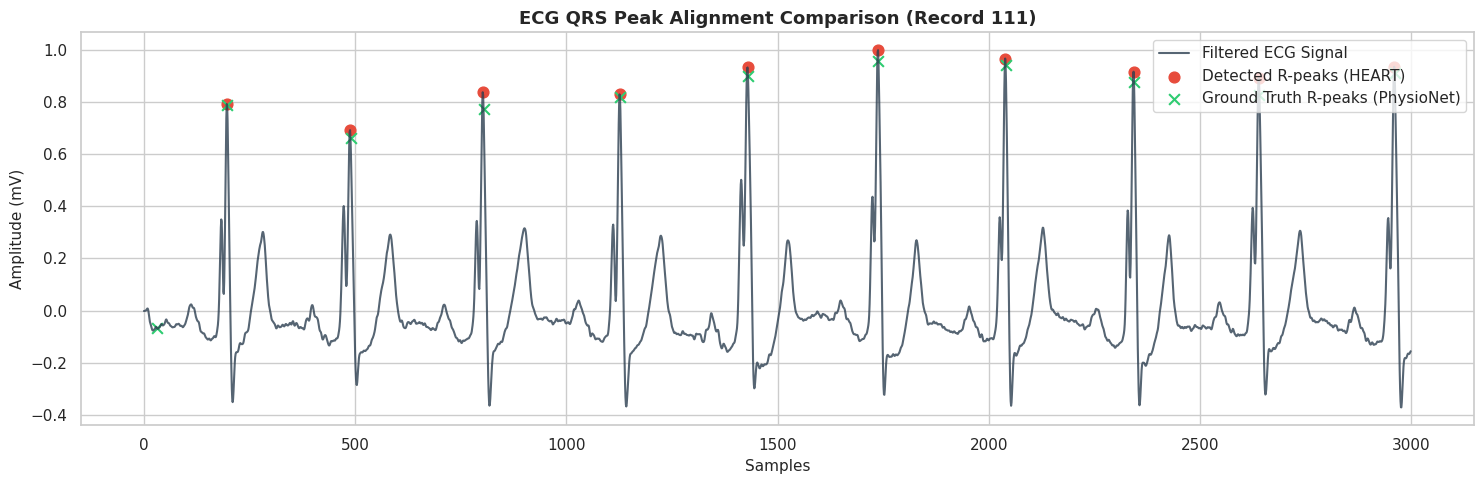

In [5]:
# Load record 111 for validation testing
record_test_id = '111'
filtered_ecg = np.load(os.path.join(default_dir, f"{record_test_id}_filtered.npy"))[:, 0]
ann_test = np.load(os.path.join(default_dir, f"{record_test_id}_annotations.npz"))
true_peaks = ann_test['indices']
fs = 360

# --- STAGE 1: Custom Pan-Tompkins ---
# A. Temporal derivative
diff_ecg = np.diff(filtered_ecg)

# B. Squaring operation
squared_ecg = diff_ecg ** 2

# C. Moving Window Integration (150 ms = 54 samples at 360 Hz)
window_len = int(0.15 * fs)
integrated_ecg = np.convolve(squared_ecg, np.ones(window_len)/window_len, mode='same')

# D. Peak detection on integrated envelope
# Minimum peak distance of ~200 ms prevents multiple detections on the same beat (physiological limit ~300 bpm)
min_distance = int(fs * 0.2) 
dynamic_threshold = np.mean(integrated_ecg)
peaks_env, _ = signal.find_peaks(integrated_ecg, distance=min_distance, prominence=dynamic_threshold)

# --- STAGE 2: Local alignment on the actual R-peak of the filtered ECG ---
aligned_peaks = []
search_win = int(0.1 * fs) # 100 ms local search window
for p in peaks_env:
    start = max(0, p - search_win)
    end = min(len(filtered_ecg), p + search_win)
    local_max = start + np.argmax(filtered_ecg[start:end])
    aligned_peaks.append(local_max)
detected_peaks = np.array(aligned_peaks)

# --- STAGE 3: Clinical Detection Accuracy Evaluation (Tolerance window = 50 ms = 18 samples) ---
tolerance = int(0.05 * fs)
matched_count = 0
for tp in true_peaks:
    distances = np.abs(detected_peaks - tp)
    if len(distances) > 0 and np.min(distances) <= tolerance:
        matched_count += 1
accuracy = (matched_count / len(true_peaks)) * 100

print(f"=== QRS DETECTOR VALIDATION (Record {record_test_id}) ===")
print(f"Ground Truth beats (cardiologists): {len(true_peaks)}")
print(f"Detected beats (HEART detector):     {len(detected_peaks)}")
print(f"Matched beats within tolerance:       {matched_count} (tolerance: {tolerance} samples)")
print(f"Detection Sensitivity/Accuracy:       {accuracy:.2f}%")

# Plot a representative segment of the signal comparing detected and ground truth peaks
plt.figure(figsize=(15, 5))
plt.plot(filtered_ecg[:3000], label="Filtered ECG Signal", color='#2c3e50', alpha=0.8)
plt.scatter(detected_peaks[detected_peaks < 3000], filtered_ecg[detected_peaks[detected_peaks < 3000]], 
            color='#e74c3c', marker='o', s=60, label="Detected R-peaks (HEART)")
plt.scatter(true_peaks[true_peaks < 3000], filtered_ecg[true_peaks[true_peaks < 3000]], 
            color='#2ecc71', marker='x', s=60, label="Ground Truth R-peaks (PhysioNet)")
plt.title(f"ECG QRS Peak Alignment Comparison (Record {record_test_id})", fontsize=13, fontweight='bold')
plt.xlabel("Samples", fontsize=11)
plt.ylabel("Amplitude (mV)", fontsize=11)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()


## 3. State-of-the-Art (SOTA) Heartbeat Feature Extraction
For each aligned heartbeat, we extract a **9-dimensional feature vector** designed to capture cardiac rhythm, QRS morphology, and multi-resolution spectral characteristics.

### A. Temporal / Rhythm Features (Local HRV)
Arrhythmias are strongly correlated with variations in the timing of cardiac depolarizations. For instance, premature ventricular contractions (PVCs) typically present a shortened pre-ectopic interval followed by a compensatory pause.
1. **`Pre_RR_sec`**: The time interval between the current and the preceding R-peak:
   $$\text{Pre\_RR} = \frac{R(i) - R(i-1)}{f_s}$$
2. **`Post_RR_sec`**: The time interval between the current and the succeeding R-peak:
   $$\text{Post\_RR} = \frac{R(i+1) - R(i)}{f_s}$$
3. **`RR_Ratio`**: The ratio representing relative prematurity:
   $$\text{RR\_Ratio} = \frac{\text{Pre\_RR\_sec}}{\text{Post\_RR\_sec}}$$
4. **`Local_RR_mean`**: The running average of the RR intervals over the last 10 beats, acting as a patient-specific baseline to normalize heart rate variation.
5. **`Local_HRV_std`**: The standard deviation of the RR intervals over the last 10 beats, measuring short-term rhythm variability.

### B. Morphological & Statistical Features
Pathological beats, such as ventricular ectopics, propagate through slower myocardial pathways rather than the specialized His-Purkinje system, resulting in prolonged and distorted QRS complexes.

6. **`R_Amplitude_mV`**: The absolute amplitude of the R-peak in millivolts.

7. **`QRS_Skewness`**: The third standardized moment, representing the asymmetry of the amplitude distribution within a 200 ms window centered on the R-peak:
   $$\text{Skewness} = \frac{\frac{1}{N} \sum (x_t - \mu)^3}{\sigma^3}$$
8. **`QRS_Kurtosis`**: The fourth standardized moment, measuring the tailedness of the distribution within the QRS window and highlighting abnormal broadening of the QRS complex:
   $$\text{Kurtosis} = \frac{\frac{1}{N} \sum (x_t - \mu)^4}{\sigma^4} - 3$$

### C. Spectral Features via Discrete Wavelet Transform (DWT)
The **Discrete Wavelet Transform (DWT)** provides a multi-resolution analysis of the ECG signal, localizing spectral components in both time and frequency. A 3-level decomposition using the **Daubechies 4 (db4)** mother wavelet partitions the signal spectrum into approximation ($A_3$) and detail ($D_1$, $D_2$, $D_3$) coefficients.

9. **`Wavelet_Energy`**: The sum of squared detail coefficients across all three decomposition levels:
   $$E_{wavelet} = \sum_{n} (D_1[n])^2 + \sum_{n} (D_2[n])^2 + \sum_{n} (D_3[n])^2$$
This feature measures high-frequency spectral content, which is typically elevated and dispersed in ectopic or fusion complexes compared to normal, fast-conducting beats.


In [6]:
# Define the standardized Inter-Patient Split protocol (De Chazal et al.)
# This partitions the 45 patients into two disjoint, independent sets
ds1_train = ['101', '106', '108', '109', '112', '114', '115', '116', '118', '119', '122', '124', '201', '203', '205', '207', '208', '209', '215', '220', '223', '230']
ds2_test = ['100', '103', '104', '105', '111', '113', '117', '121', '123', '200', '202', '210', '212', '213', '214', '219', '221', '222', '228', '231', '232', '233', '234']

file_list = sorted([f for f in os.listdir(default_dir) if f.endswith('_filtered.npy')])
record_ids = [f.split('_')[0] for f in file_list]

dataset_rows = []
tolerance_alignment = int(0.05 * fs) # 50 ms tolerance window for label alignment

print("Starting SOTA Feature Extraction across the selected clinical records...")
start_time = time.time()

for record_id in record_ids:
    if record_id not in ds1_train and record_id not in ds2_test:
        continue # Exclude non-standard records (102, 107, 217, 229)
        
    split_group = 'Train' if record_id in ds1_train else 'Test'
    
    # Load filtered ECG signal and clinical annotations
    signal_data = np.load(os.path.join(default_dir, f"{record_id}_filtered.npy"))[:, 0]
    annotations = np.load(os.path.join(default_dir, f"{record_id}_annotations.npz"))
    true_peaks = annotations['indices']
    labels = annotations['labels']
    
    # Run custom QRS detection on current record
    diff_s = np.diff(signal_data)
    squared_s = diff_s ** 2
    integrated_s = np.convolve(squared_s, np.ones(window_len)/window_len, mode='same')
    peaks_env_s, _ = signal.find_peaks(integrated_s, distance=min_distance, prominence=np.mean(integrated_s))
    
    # Align peaks locally on real R-wave amplitude maximums
    aligned_peaks_s = []
    for p in peaks_env_s:
        start = max(0, p - search_win)
        end = min(len(signal_data), p + search_win)
        aligned_peaks_s.append(start + np.argmax(signal_data[start:end]))
    detected_peaks_s = np.array(aligned_peaks_s)
    
    recent_rr = []
    
    # Iterate while excluding first and last detected beats to compute Pre-RR/Post-RR safely
    for i in range(1, len(detected_peaks_s) - 1):
        r_peak = detected_peaks_s[i]
        prev_r = detected_peaks_s[i-1]
        next_r = detected_peaks_s[i+1]
        
        # Synchronize detected peak with cardiologists' ground truth annotations
        dists = np.abs(true_peaks - r_peak)
        if len(dists) == 0 or np.min(dists) > tolerance_alignment:
            continue # If the peak does not match any clinical annotation within tolerance, discard it
            
        beat_label = labels[np.argmin(dists)]
        
        # 1. Dynamic Temporal Features (Local HRV)
        pre_rr = (r_peak - prev_r) / fs
        post_rr = (next_r - r_peak) / fs
        rr_ratio = pre_rr / post_rr if post_rr > 0 else 1.0
        
        recent_rr.append(pre_rr)
        local_mean = np.mean(recent_rr[-10:]) if len(recent_rr) >= 10 else pre_rr
        local_hrv = np.std(recent_rr[-10:]) if len(recent_rr) >= 10 else 0.0
        
        # 2. QRS Complex Morphological Window (200 ms centered on R-peak)
        win_size = int(0.1 * fs)
        qrs_start = max(0, r_peak - win_size)
        qrs_end = min(len(signal_data), r_peak + win_size)
        qrs_window = signal_data[qrs_start:qrs_end]
        
        if len(qrs_window) < (win_size * 2):
            continue # Edge case guard for beats too close to record boundary
            
        # 3. Morphological & Statistical Features
        r_amp = signal_data[r_peak]
        skewness = stats.skew(qrs_window)
        kurtosis = stats.kurtosis(qrs_window)
        
        # 4. Multi-resolution Spectral Features via 3-Level DWT (Daubechies 4)
        coeffs = pywt.wavedec(qrs_window, 'db4', level=3)
        # Calculate high-frequency detail coefficients spectral energy
        wave_energy = np.sum(np.square(coeffs[1])) + np.sum(np.square(coeffs[2])) + np.sum(np.square(coeffs[3]))
        
        dataset_rows.append({
            'Record_ID': record_id,
            'Dataset_Split': split_group,
            'Pre_RR_sec': pre_rr,
            'Post_RR_sec': post_rr,
            'RR_Ratio': rr_ratio,
            'Local_RR_mean': local_mean,
            'Local_HRV_std': local_hrv,
            'R_Amplitude_mV': r_amp,
            'QRS_Skewness': skewness,
            'QRS_Kurtosis': kurtosis,
            'Wavelet_Energy': wave_energy,
            'Label': beat_label
        })

print(f"Feature extraction completed successfully in {time.time() - start_time:.2f} seconds.")


Starting SOTA Feature Extraction across the selected clinical records...
Feature extraction completed successfully in 32.95 seconds.


## 4. Clinical Class Mapping (AAMI Standard) and Inter-Patient Split

The original annotations in the PhysioNet MIT-BIH Arrhythmia Database use 19 different symbols to designate electrophysiological heartbeat types. To align with international clinical guidelines established by the **AAMI (Association for the Advancement of Medical Instrumentation)**, these symbols are mapped to **4 clinical macro-classes**:

* **`N` (Normal / Bundle Branch Block)**: Normal conduction beats and bundle branch blocks (original symbols: `N`, `L`, `R`, `e`, `j`).
* **`S` (Supraventricular Ectopic - SVEB)**: Supraventricular premature beats (original symbols: `A`, `a`, `J`, `S`).
* **`V` (Ventricular Ectopic - VEB)**: Premature ventricular contractions (original symbols: `V`, `E`).
* **`F` (Fusion beat)**: Beats resulting from the fusion of normal and ventricular activation (original symbol: `F`).

Consistent with academic literature, paced beats, unclassifiable beats, and noise artifacts (labeled `/`, `f`, `Q`) are excluded to avoid training bias.

### Inter-Patient Split Protocol (De Chazal)
Traditional intra-patient validation schemes (e.g., random K-fold cross-validation on mixed beats) introduce substantial **data leakage** because heartbeats from the same patient populate both training and test subsets. Since ECG morphology exhibits high patient specificity, classifiers tend to memorize individual patient characteristics rather than generalizable arrhythmic features, leading to artificially inflated performance metrics.

To ensure realistic generalization, we implement the **De Chazal et al.** partition, dividing the 45 analyzed patients into two disjoint sets:
* **Dataset 1 (Train - DS1)**: 22 records utilized for model training and hyperparameter optimization.
* **Dataset 2 (Test - DS2)**: 23 records reserved strictly for unseen testing.


In [7]:
df_raw = pd.DataFrame(dataset_rows)

# AAMI mapping dictionary
aami_mapping = {
    'N': 'N', 'L': 'N', 'R': 'N', 'e': 'N', 'j': 'N',
    'A': 'S', 'a': 'S', 'J': 'S', 'S': 'S',
    'V': 'V', 'E': 'V', 'F': 'F'
}

df_raw['AAMI_Class'] = df_raw['Label'].map(aami_mapping)
# Drop unmapped beats (e.g. paced, unclassifiable or artifacts)
df_clean = df_raw.dropna(subset=['AAMI_Class'])

# Save the final dataset for the Machine Learning training stage
output_csv = os.path.join(default_dir, 'ECG_Features_Complete_SOTA.csv')
df_clean.to_csv(output_csv, index=False)

print("=== EXTRACTED DATASET STATISTICS ===")
print(f"File saved to: {output_csv}")
print(f"Total extracted beats: {len(df_clean)}")
print(f"Feature matrix shape: {df_clean.shape}")
print("\nAAMI class distribution:")
print(df_clean['AAMI_Class'].value_counts())
print("\nDataset distribution across disjoint patient groups (De Chazal split):")
print(df_clean['Dataset_Split'].value_counts())


=== EXTRACTED DATASET STATISTICS ===
File saved to: ../data/ECG_Features_Complete_SOTA.csv
Total extracted beats: 96832
Feature matrix shape: (96832, 13)

AAMI class distribution:
AAMI_Class
N    87791
V     5615
S     2643
F      783
Name: count, dtype: int64

Dataset distribution across disjoint patient groups (De Chazal split):
Dataset_Split
Test     48869
Train    47963
Name: count, dtype: int64
